# Hausa Sentiment - Step 4: Transformer + LoRA

This notebook fine-tunes `Davlan/afro-xlmr-mini` for three-class Hausa sentiment classification using LoRA. Training uses `train`, model selection uses `dev_noleak` macro-F1, and the official test set is evaluated once for the selected checkpoint.

**Runtime:** Google Colab with GPU enabled. If GPU memory is insufficient, reduce `BATCH_SIZE` or `MAX_LEN` before reducing the number of epochs.


In [3]:
!pip -q install -U transformers datasets evaluate peft accelerate sentencepiece scikit-learn pandas "torchao>=0.16.0"

from pathlib import Path
import json, os, random, time
import numpy as np
import pandas as pd
import torch
from datasets import Dataset
from peft import LoraConfig, TaskType, get_peft_model
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from transformers import AutoModelForSequenceClassification, AutoTokenizer, DataCollatorWithPadding, Trainer, TrainingArguments, set_seed

SEED = 42
set_seed(SEED); random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("A CUDA GPU is required for this notebook. Enable Runtime > Change runtime type > T4 GPU in Colab.")
print("GPU:", torch.cuda.get_device_name(0))

required = ["afrisenti_hau_train.csv", "afrisenti_hau_dev_noleak.csv", "afrisenti_hau_test.csv"]
candidates = [Path("/content/hausa-sentiment"), Path("/content"), Path.cwd(), Path.cwd().parent]
ROOT = PROC = None
for root in candidates:
    for proc in (root / "data" / "processed", root):
        if all((proc / name).exists() for name in required):
            ROOT, PROC = root, proc; break
    if PROC is not None: break
if PROC is None:
    raise FileNotFoundError("Processed AfriSenti CSVs were not found in the Colab or repository layouts.")
MODELS, RESULTS = ROOT / "models", ROOT / "results"
MODELS.mkdir(parents=True, exist_ok=True); RESULTS.mkdir(parents=True, exist_ok=True)
print("ROOT:", ROOT); print("PROC:", PROC)


GPU: Tesla T4
ROOT: /content
PROC: /content


## 1. Configuration and data

The tokenizer receives `text_clean`, while the label IDs remain fixed as positive=0, neutral=1, and negative=2. The tokenizer and model are never fitted on the test set.


In [4]:
MODEL_NAME = "Davlan/afro-xlmr-mini"
MAX_LEN = 96
BATCH_SIZE = 16
GRAD_ACCUM = 2
EPOCHS = 3
LEARNING_RATE = 2e-4
LORA_R = 8
LORA_ALPHA = 16
LORA_DROPOUT = 0.1
LABELS = ["positive", "neutral", "negative"]

train_frame = pd.read_csv(PROC / "afrisenti_hau_train.csv")
dev_frame = pd.read_csv(PROC / "afrisenti_hau_dev_noleak.csv")
test_frame = pd.read_csv(PROC / "afrisenti_hau_test.csv")
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_dataset(frame):
    frame = frame[["text_clean", "label_id"]].rename(columns={"text_clean": "text", "label_id": "labels"})
    return Dataset.from_pandas(frame, preserve_index=False)

train_ds, dev_ds, test_ds = map(to_dataset, (train_frame, dev_frame, test_frame))
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)
train_ds = train_ds.map(tokenize, batched=True, remove_columns=["text"])
dev_ds = dev_ds.map(tokenize, batched=True, remove_columns=["text"])
test_ds = test_ds.map(tokenize, batched=True, remove_columns=["text"])
data_collator = DataCollatorWithPadding(tokenizer=tokenizer, pad_to_multiple_of=8)
print(f"rows: train={len(train_ds)}, dev_noleak={len(dev_ds)}, test={len(test_ds)}")


config.json:   0%|          | 0.00/721 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/435 [00:00<?, ?B/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/9.08M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Map:   0%|          | 0/14172 [00:00<?, ? examples/s]

Map:   0%|          | 0/2462 [00:00<?, ? examples/s]

Map:   0%|          | 0/5303 [00:00<?, ? examples/s]

rows: train=14172, dev_noleak=2462, test=5303


## 2. LoRA model and metrics

LoRA freezes the pretrained encoder and trains low-rank updates in the attention query/value projections plus the classification head. This reduces trainable parameters while retaining the encoder's multilingual representations.


In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label={i: label for i, label in enumerate(LABELS)},
    label2id={label: i for i, label in enumerate(LABELS)},
)
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=LORA_R,
    lora_alpha=LORA_ALPHA,
    lora_dropout=LORA_DROPOUT,
    target_modules=["query", "value"],
    modules_to_save=["classifier"],
)
model = get_peft_model(model, lora_config)
model.print_trainable_parameters()

def metrics_fn(eval_pred):
    predictions, labels = eval_pred
    predictions = np.argmax(predictions, axis=-1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(labels, predictions, average="macro"),
        "f1_positive": f1_score(labels, predictions, labels=[0], average="macro"),
        "f1_neutral": f1_score(labels, predictions, labels=[1], average="macro"),
        "f1_negative": f1_score(labels, predictions, labels=[2], average="macro"),
    }


model.safetensors: reconstructing file:   0%|          |  0.00B /  472MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: Davlan/afro-xlmr-mini
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 296,451 || all params: 117,938,310 || trainable%: 0.2514


In [6]:
run_id = "T1_afroxlmr_lora"
output_dir = MODELS / run_id
training_args = TrainingArguments(
    output_dir=str(output_dir),
    learning_rate=LEARNING_RATE,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    gradient_accumulation_steps=GRAD_ACCUM,
    num_train_epochs=EPOCHS,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_strategy="steps",
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    fp16=True,
    report_to="none",
    seed=SEED,
)
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=dev_ds,
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=metrics_fn,
)
started = time.time()
trainer.train()
train_seconds = time.time() - started
dev_metrics = trainer.evaluate(dev_ds, metric_key_prefix="dev_noleak")
print("training_seconds:", round(train_seconds, 1))
print(json.dumps(dev_metrics, indent=2, default=float))


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,F1 Positive,F1 Neutral,F1 Negative
1,1.675804,0.808940,0.610885,0.608972,0.773190,0.557495,0.496231
2,1.568596,0.758718,0.647441,0.647361,0.803692,0.602452,0.535939
3,1.523675,0.742113,0.662876,0.661960,0.808805,0.636463,0.540613


Training Loss,Validation Loss,Epoch,Noleak Loss,Noleak Accuracy,Noleak Macro F1,Noleak F1 Positive,Noleak F1 Neutral,Noleak F1 Negative
1.523675,No log,3,0.742113,0.662876,0.661960,0.808805,0.636463,0.540613


training_seconds: 132.3
{
  "dev_noleak_loss": 0.7421132326126099,
  "dev_noleak_accuracy": 0.6628757108042242,
  "dev_noleak_macro_f1": 0.661960143395695,
  "dev_noleak_f1_positive": 0.8088050314465409,
  "dev_noleak_f1_neutral": 0.6364628820960698,
  "dev_noleak_f1_negative": 0.5406125166444741
}


## 3. Final test evaluation and artifact export

This is the only test evaluation in the notebook. The checkpoint was selected by `dev_noleak` macro-F1 through `load_best_model_at_end=True`.


In [7]:
test_metrics = trainer.evaluate(test_ds, metric_key_prefix="test")
pred_output = trainer.predict(test_ds)
test_predictions = np.argmax(pred_output.predictions, axis=-1)
test_labels = np.asarray(test_ds["labels"])
cm = confusion_matrix(test_labels, test_predictions).tolist()
artifact_dir = MODELS / "transformer_lora_best"
artifact_dir.mkdir(parents=True, exist_ok=True)
trainer.save_model(str(artifact_dir))
tokenizer.save_pretrained(str(artifact_dir))
summary = {
    "run_id": run_id,
    "base_model": MODEL_NAME,
    "max_len": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "lora_r": LORA_R,
    "lora_alpha": LORA_ALPHA,
    "lora_dropout": LORA_DROPOUT,
    "target_modules": ["query", "value"],
    "train_seconds": round(train_seconds, 2),
    "trainable_params": sum(p.numel() for p in model.parameters() if p.requires_grad),
    "total_params": sum(p.numel() for p in model.parameters()),
    "dev_noleak": {key.removeprefix("dev_noleak_"): float(value) for key, value in dev_metrics.items() if key.startswith("dev_noleak_")},
    "test": {key.removeprefix("test_"): float(value) for key, value in test_metrics.items() if key.startswith("test_")},
    "confusion_matrix": cm,
}
with open(RESULTS / "transformer_lora_metrics.json", "w") as handle: json.dump(summary, handle, indent=2)
with open(RESULTS / "transformer_lora_training_args.json", "w") as handle: json.dump(training_args.to_dict(), handle, indent=2, default=str)
print(json.dumps(summary, indent=2))
print("saved adapter/tokenizer:", artifact_dir)

Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,F1 Positive,F1 Neutral,F1 Negative
1.523675,0.826443,3,0.602112,0.601296,0.743295,0.495407,0.565186


{
  "run_id": "T1_afroxlmr_lora",
  "base_model": "Davlan/afro-xlmr-mini",
  "max_len": 96,
  "batch_size": 16,
  "gradient_accumulation_steps": 2,
  "epochs": 3,
  "learning_rate": 0.0002,
  "lora_r": 8,
  "lora_alpha": 16,
  "lora_dropout": 0.1,
  "target_modules": [
    "query",
    "value"
  ],
  "train_seconds": 132.27,
  "trainable_params": 296451,
  "total_params": 117938310,
  "dev_noleak": {
    "loss": 0.7421132326126099,
    "accuracy": 0.6628757108042242,
    "macro_f1": 0.661960143395695,
    "f1_positive": 0.8088050314465409,
    "f1_neutral": 0.6364628820960698,
    "f1_negative": 0.5406125166444741
  },
  "test": {
    "loss": 0.8264433145523071,
    "accuracy": 0.6021120120686404,
    "macro_f1": 0.6012959725779472,
    "f1_positive": 0.7432950191570882,
    "f1_neutral": 0.4954068241469816,
    "f1_negative": 0.5651860744297719
  },
  "confusion_matrix": [
    [
      1261,
      169,
      325
    ],
    [
      130,
      755,
      904
    ],
    [
      247,
     

## Visual summary of the LoRA experiment

This plot visualizes the recorded development and official test metrics from `dev_metrics` and `test_metrics`.


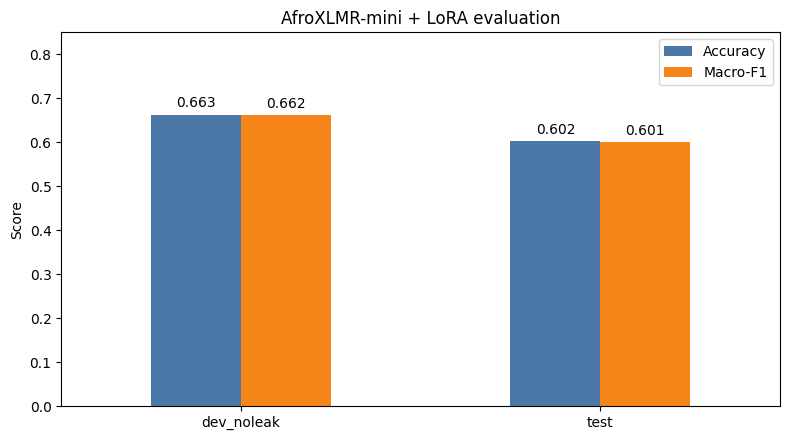

In [8]:
import matplotlib.pyplot as plt

# Visual summary: recorded LoRA development and test metrics
lora_viz = pd.DataFrame({
    "Split": ["dev_noleak", "test"],
    "Accuracy": [dev_metrics["dev_noleak_accuracy"], test_metrics["test_accuracy"]],
    "Macro-F1": [dev_metrics["dev_noleak_macro_f1"], test_metrics["test_macro_f1"]],
}).set_index("Split")

ax = lora_viz.plot(kind="bar", figsize=(8, 4.5), color=["#4c78a8", "#f58518"])
ax.set_title("AfroXLMR-mini + LoRA evaluation")
ax.set_xlabel("")
ax.set_ylabel("Score")
ax.set_ylim(0, 0.85)
ax.tick_params(axis="x", rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", padding=3)
plt.tight_layout()
plt.show()
